<a href="https://colab.research.google.com/github/Fannno/GenAI-Practice/blob/main/week01/flower_drawing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 用函數畫小花

## 1. 作品說明
這次作業用玫瑰曲線畫出三朵花，再加上花莖和葉子。

三朵花分別使用粉紅、紫色和青綠色，每朵疊上三層大小和角度不同的花瓣，讓畫面比較有層次。

## 2. 套件與公式
先匯入繪圖需要的套件。

In [ ]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

花瓣使用的玫瑰曲線公式是：

$$r=a\cos(k\theta)$$

* $a$ 控制花的大小，這裡使用正值。

* $k$ 是正整數，用來控制花瓣數。

每一層曲線中，$k$ 是奇數時有 $k$ 片花瓣，偶數時有 $2k$ 片。

例如: $k=5$ 是五片，$k=4$ 則是八片。

讓角度 $\theta$ 從 $0$ 變到 $2\pi$，再把它轉成平面座標：

$$x=r\cos\theta,\qquad y=r\sin\theta$$

這裡的 $x$ 和 $y$ 都是隨著角度算出來的，屬於參數式曲線，和課堂上的直線圖不同。

同一個 $x$ 可以對應不同的 $y$。

## 3. 小花繪圖
每朵花都由三層大小和角度不同的玫瑰曲線疊成，再將三朵花安排在不同位置。

花莖使用正弦函數做出一點彎曲，葉子則用橢圓來畫。

加上花心位置 $(c_x,c_y)$ 和旋轉角度 $\phi$ 後，公式為：

$$x=c_x+r\cos(\theta+\phi),\qquad y=c_y+r\sin(\theta+\phi)$$

程式最後三次「畫花」的設定，分別控制三朵花的位置、大小、花瓣參數和顏色。

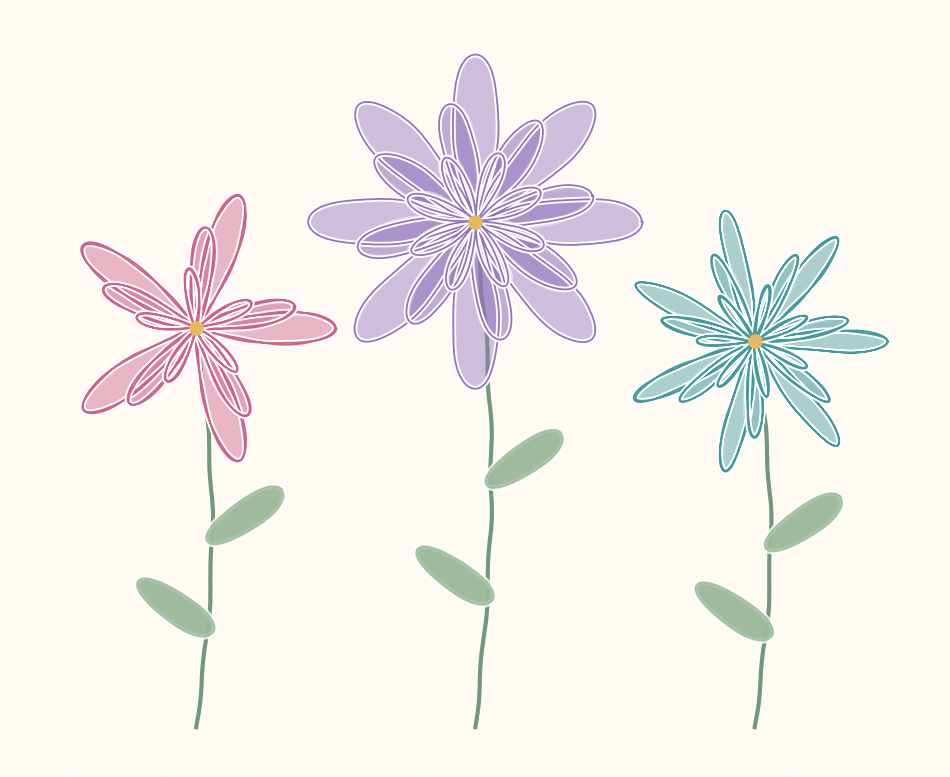

In [ ]:
# 先設定畫圖風格和角度範圍
plt.rcdefaults()
plt.xkcd()
theta = np.linspace(0, 2 * np.pi, 2400)

fig, ax = plt.subplots(figsize=(10, 8), facecolor="#fffaf4")
ax.set_facecolor("#fffaf4")

# 畫葉子會用到的角度
角度 = np.linspace(0, 2 * np.pi, 240)

def 畫花(cx, cy, 大小, k, 顏色):
    # 先畫花莖，讓它彎曲一點比較好看
    t = np.linspace(0, 1, 300)
    莖x = cx + 0.12 * np.sin(np.pi * t)
    莖y = -2.6 + (cy + 2.6) * t
    ax.plot(莖x, 莖y, color="#72977b", linewidth=3, zorder=1)

    # 在花莖左右各加一片葉子
    for 高度, 方向 in [(0.30, -1), (0.53, 1)]:
        葉心x = cx + 0.12 * np.sin(np.pi * 高度) + 方向 * 0.25
        葉心y = -2.6 + (cy + 2.6) * 高度
        u = 0.34 * np.cos(角度)
        v = 0.12 * np.sin(角度)
        phi = 方向 * 0.6
        葉x = 葉心x + u * np.cos(phi) - v * np.sin(phi)
        葉y = 葉心y + u * np.sin(phi) + v * np.cos(phi)
        ax.fill(葉x, 葉y, color="#9ab99b", alpha=0.8)

    # 花瓣疊三層，越裡面越小，角度也讓它稍微轉一下
    for 比例, 旋轉, 透明度 in [(1, 0, 0.25), (0.72, 0.22, 0.35), (0.43, 0.44, 0.5)]:
        r = 大小 * 比例 * np.cos(k * theta)
        x = cx + r * np.cos(theta + 旋轉)
        y = cy + r * np.sin(theta + 旋轉)
        ax.fill(x, y, color=顏色, alpha=透明度, zorder=3)
        ax.plot(x, y, color=顏色, linewidth=1.3, zorder=4)

    # 中間加一個黃色的花心
    ax.scatter([cx], [cy], s=90, color="#e7b85c", zorder=5)

# 畫出三朵不同位置、大小和顏色的花
畫花(-2.1, 0.4, 1.05, 5, "#ce6288")
畫花(0, 1.2, 1.25, 4, "#9174bf")
畫花(2.1, 0.3, 1.0, 7, "#439a99")

# 讓花的比例正常，再把座標軸隱藏
ax.set_aspect("equal")
ax.set_xlim(-3.5, 3.5)
ax.set_ylim(-2.9, 2.8)
ax.axis("off")
fig.tight_layout()
plt.show()

## 4. 上課筆記

Colab 支援 **Markdown** 標記語言與 **LaTeX**（輸入數學式）語法。

### 常用核心套件
* **numpy**：數值計算與矩陣處理核心套件
* **pandas**：結構化資料處理工具（Python 界的 Excel）
* **matplotlib**：資料視覺化與圖表繪製套件

### LaTeX 數學式語法
* **行內公式（Inline Mode）**：使用單錢字號 `$ ... $`，公式會與前後文字混排在同一行，不主動跳行。
* **置中獨立公式（Display Mode）**：使用雙錢字號 `$$ ... $$`，公式會單獨獨立成行，並自動居中排列。

### xkcd() 函數說明
* `plt.xkcd()`：向著名網路漫畫 *xkcd* 致敬，呼叫後會將圖表線條與字體轉為手繪線條的漫畫風格進行繪圖。